# T3 — Features temporales y baselines

Validación temporal: train 2006–2020, validación 2021–2022, test 2023–2025 (`src/features.py`). Modelos: media histórica por cultivo, LinearRegression, RandomForest (`src/baseline.py`).

## 1. Features y splits

In [1]:
import json
import sys
from pathlib import Path
sys.path.insert(0, str(Path('../src')))
from features import build_features, load_clean, prepare_xy

df = load_clean()
m = build_features(df)
splits, gmean = prepare_xy(m)
for name, (X, y, meta) in splits.items():
    print(f'{name}: {len(y):,} filas, {X.shape[1]} features, media y={y.mean():.2f}')
print('features:', list(splits['train'][0].columns))

train: 237,255 filas, 30 features, media y=9.40
val: 47,007 filas, 30 features, media y=10.68
test: 70,644 filas, 30 features, media y=11.16
features: ['area_sembrada_log', 'is_B', 'is_anual', 'hist_len', 'r_lag1', 'r_lag2', 'r_roll3', 'r_roll5', 'cultivo_norm_te', 'municipio_norm_te', 'cod_dep_te', 'grupo_norm_te', 'grupo__cereales', 'grupo__cultivos para condimentos, bebidas medicinales y aromaticas', 'grupo__cultivos tropicales tradicionales', 'grupo__fibras', 'grupo__flores y follajes', 'grupo__forestales', 'grupo__frutales', 'grupo__hortalizas', 'grupo__leguminosas', 'grupo__oleaginosas', 'grupo__otros permanentes', 'grupo__otros transitorios', 'grupo__plantas aromaticas, condimentarias y medicinales', 'grupo__raices y tuberculos', 'grupo__tuberculos y platanos', 'ciclo__anual', 'ciclo__permanente', 'ciclo__transitorio']


## 2. Métricas de los baselines (test 2023–2025)

MAPE se distorsiona con rendimientos bajos: se reporta también MedAPE. Baseline a superar por el modelo final (T4): **RandomForest (RMSE 5,40; R² 0,88)**.

In [2]:
res = json.loads(Path('../models/baseline_metrics.json').read_text())
import pandas as pd
rows = []
for model in ['media_historica', 'linear', 'random_forest']:
    for split in ['val', 'test']:
        x = res[model][split]
        rows.append({'modelo': model, 'corte': split,
                     'RMSE': round(x['rmse'], 3), 'MAE': round(x['mae'], 3),
                     'R2': round(x['r2'], 4),
                     'MedAPE%': round(x['medape_pct'], 1),
                     'MAPE%': round(x['mape_pct'], 1),
                     'n': x['n']})
print(pd.DataFrame(rows).to_string(index=False))

         modelo corte   RMSE   MAE     R2  MedAPE%  MAPE%     n
media_historica   val  9.772 4.970 0.5614     36.4   77.4 47007
media_historica  test 10.020 5.017 0.5760     34.9   69.1 70644
         linear   val  6.759 3.445 0.7902     28.8   97.2 47007
         linear  test  6.058 2.978 0.8450     22.6   84.6 70644
  random_forest   val  6.071 2.627 0.8308     16.6   46.0 47007
  random_forest  test  5.398 2.265 0.8770     14.5   36.7 70644


## 3. Predicho vs real (test, RandomForest)

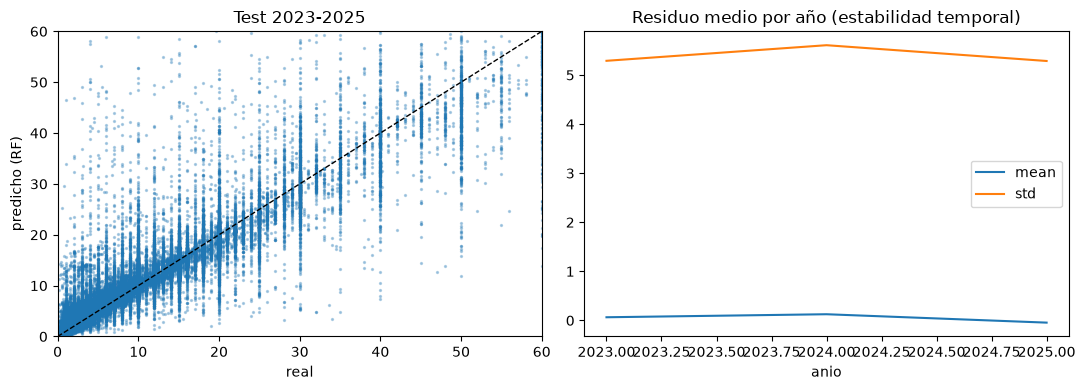

count    70644.000000
mean         2.265160
std          4.899399
min          0.000033
25%          0.308733
50%          0.850417
75%          2.163025
max        107.156100


In [3]:
import matplotlib.pyplot as plt
pred = pd.read_csv('../models/baseline_test_predictions.csv')
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(pred.y_true, pred.y_pred_rf, s=2, alpha=.3)
ax[0].plot([0, 60], [0, 60], 'k--', lw=1)
ax[0].set_xlabel('real'); ax[0].set_ylabel('predicho (RF)')
ax[0].set_title('Test 2023-2025'); ax[0].set_xlim(0, 60); ax[0].set_ylim(0, 60)
pred['res'] = pred.y_pred_rf - pred.y_true
pred.groupby('anio')['res'].agg(['mean', 'std']).plot(ax=ax[1])
ax[1].set_title('Residuo medio por año (estabilidad temporal)')
plt.tight_layout(); plt.show()
print(pred['res'].abs().describe().to_string())

## Conclusiones T3

- La serie es predecible con historia: media histórica da R² 0,58; los lags/rolling elevan a **R² 0,85 (lineal) – 0,88 (RF)**.
- RF es el baseline a superar en T4 (LightGBM/XGBoost + Optuna + SHAP).
- El error crece con rendimientos altos (cola pesada) → en T4 se evalúa predicir en log o por grupo.
- Pregunta abierta para T4: ¿el encoding por municipio captura edafoclimática o sobreajusta municipios con poca historia? Se regula con suavizado (m=10) y se mide con walk-forward.